# DistilBERT Emotion Classification

Fine-tuning `distilbert-base-uncased` on a subset of the `dair-ai/emotion` dataset (1600 train, 400 test).

In [1]:
%pip install -q transformers datasets accelerate scikit-learn torch matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch
from datasets import load_dataset
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
)
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
)

SEED = 42
MODEL_NAME = "distilbert-base-uncased"
DATASET_NAME = "dair-ai/emotion"
TRAIN_SIZE = 1600
TEST_SIZE = 400
MAX_LENGTH = 64

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device}")

c:\Users\adile\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cpu


In [3]:
raw_dataset = load_dataset(DATASET_NAME)
label_names = raw_dataset["train"].features["label"].names
num_labels = len(label_names)
id2label = {i: name for i, name in enumerate(label_names)}
label2id = {name: i for i, name in enumerate(label_names)}

train_dataset = raw_dataset["train"].shuffle(seed=SEED).select(range(TRAIN_SIZE))
test_dataset = raw_dataset["test"].shuffle(seed=SEED).select(range(TEST_SIZE))

print(f"Labels ({num_labels}): {label_names}")
print(f"Train samples: {len(train_dataset)}, Test samples: {len(test_dataset)}")

train_counts = Counter(train_dataset["label"])
test_counts = Counter(test_dataset["label"])
print("\nClass distribution:")
for i, name in enumerate(label_names):
    print(f"  {name:<10} train={train_counts[i]:<4} test={test_counts[i]:<4}")

print("\nSample row:", train_dataset[0])

c:\Users\adile\AppData\Local\Programs\Python\Python313\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\adile\.cache\huggingface\hub\datasets--dair-ai--emotion. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\adile\AppData\Local\Programs\Python\Python313\Lib\site-packages\huggingface_hub\file_do

Labels (6): ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']
Train samples: 1600, Test samples: 400

Class distribution:
  sadness    train=460  test=114 
  joy        train=531  test=162 
  love       train=124  test=26  
  anger      train=215  test=47  
  fear       train=206  test=36  
  surprise   train=64   test=15  

Sample row: {'text': 'while cycling in the country', 'label': 4}


In [4]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_batch(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

tokenized_train = train_dataset.map(tokenize_batch, batched=True)
tokenized_test = test_dataset.map(tokenize_batch, batched=True)
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

c:\Users\adile\AppData\Local\Programs\Python\Python313\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\adile\.cache\huggingface\hub\models--distilbert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Map: 100%|██████████| 400/400 [00:00<00:00, 11391.30 examples/s]


In [5]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "macro_f1": f1_score(labels, preds, average="macro"),
        "weighted_f1": f1_score(labels, preds, average="weighted"),
    }

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id,
)

training_args = TrainingArguments(
    output_dir="emotion_model",
    num_train_epochs=2,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=32,
    learning_rate=3e-5,
    weight_decay=0.01,
    eval_strategy="steps",
    eval_steps=25,
    logging_steps=25,
    save_strategy="no",
    report_to="none",
    seed=SEED,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_test,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

trainer.train()

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 1264.51it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
c:\Users\adile\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set

Step,Training Loss,Validation Loss,Accuracy,Macro F1,Weighted F1
25,1.632736,1.387150,0.592500,0.230993,0.486913
50,1.376836,1.143751,0.632500,0.248783,0.525996
75,1.186574,1.034944,0.642500,0.252066,0.533016
100,1.107616,1.003334,0.650000,0.254536,0.537256


c:\Users\adile\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
c:\Users\adile\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
c:\Users\adile\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


TrainOutput(global_step=100, training_loss=1.3259404182434082, metrics={'train_runtime': 625.8629, 'train_samples_per_second': 5.113, 'train_steps_per_second': 0.16, 'total_flos': 43725639685248.0, 'train_loss': 1.3259404182434082, 'epoch': 2.0})

In [6]:
predictions = trainer.predict(tokenized_test)
y_true = predictions.label_ids
y_pred = np.argmax(predictions.predictions, axis=-1)

acc = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(y_true, y_pred, average="macro")
weighted_f1 = f1_score(y_true, y_pred, average="weighted")

print(f"Accuracy:    {acc:.4f}")
print(f"Macro F1:    {macro_f1:.4f}")
print(f"Weighted F1: {weighted_f1:.4f}\n")
print(classification_report(y_true, y_pred, target_names=label_names, digits=4))

c:\Users\adile\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Accuracy:    0.6500
Macro F1:    0.2545
Weighted F1: 0.5373

              precision    recall  f1-score   support

     sadness     0.5297    0.9386    0.6772       114
         joy     0.7727    0.9444    0.8500       162
        love     0.0000    0.0000    0.0000        26
       anger     0.0000    0.0000    0.0000        47
        fear     0.0000    0.0000    0.0000        36
    surprise     0.0000    0.0000    0.0000        15

    accuracy                         0.6500       400
   macro avg     0.2171    0.3138    0.2545       400
weighted avg     0.4639    0.6500    0.5373       400



c:\Users\adile\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\adile\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\adile\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

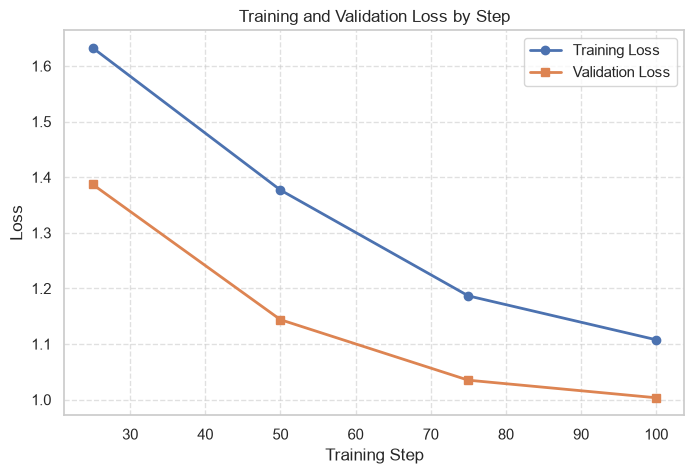

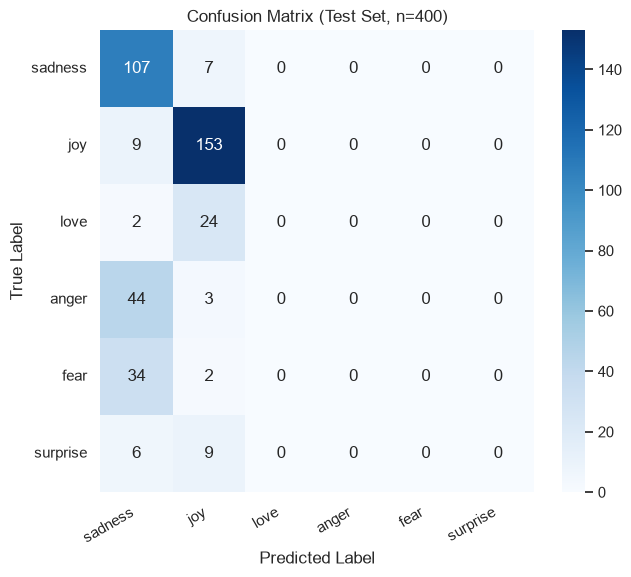

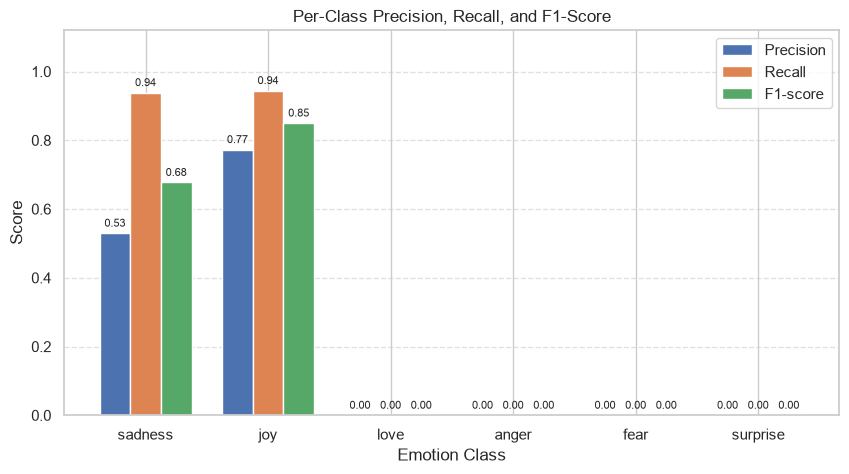

In [7]:
os.makedirs("assets", exist_ok=True)
sns.set_theme(style="whitegrid")

# 1. Training and Validation Loss Curve
train_steps = [entry["step"] for entry in trainer.state.log_history if "loss" in entry]
train_losses = [entry["loss"] for entry in trainer.state.log_history if "loss" in entry]
eval_steps = [entry["step"] for entry in trainer.state.log_history if "eval_loss" in entry]
eval_losses = [entry["eval_loss"] for entry in trainer.state.log_history if "eval_loss" in entry]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(train_steps, train_losses, marker="o", linewidth=2, label="Training Loss")
ax.plot(eval_steps, eval_losses, marker="s", linewidth=2, label="Validation Loss")
ax.set_title("Training and Validation Loss by Step")
ax.set_xlabel("Training Step")
ax.set_ylabel("Loss")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.6)
fig.savefig("assets/training_loss.png", dpi=300, bbox_inches="tight")
plt.show()

# 2. Confusion Matrix Heatmap (6x6)
cm = confusion_matrix(y_true, y_pred, labels=list(range(num_labels)))
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_names,
    yticklabels=label_names,
    ax=ax,
)
ax.set_title("Confusion Matrix (Test Set, n=400)")
ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)
fig.savefig("assets/confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

# 3. Per-Class Precision, Recall, and F1-Score Bar Chart
precision, recall, f1, _ = precision_recall_fscore_support(
    y_true, y_pred, labels=list(range(num_labels)), zero_division=0
)
x = np.arange(num_labels)
width = 0.25

fig, ax = plt.subplots(figsize=(10, 5))
bars_p = ax.bar(x - width, precision, width, label="Precision")
bars_r = ax.bar(x, recall, width, label="Recall")
bars_f = ax.bar(x + width, f1, width, label="F1-score")

for bars in (bars_p, bars_r, bars_f):
    for bar in bars:
        height = bar.get_height()
        ax.annotate(
            f"{height:.2f}",
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=8,
        )

ax.set_title("Per-Class Precision, Recall, and F1-Score")
ax.set_xlabel("Emotion Class")
ax.set_ylabel("Score")
ax.set_xticks(x)
ax.set_xticklabels(label_names)
ax.set_ylim(0, 1.12)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.6)
fig.savefig("assets/per_class_metrics.png", dpi=300, bbox_inches="tight")
plt.show()

In [8]:
sample_texts = [
    "I just got the job offer I have been waiting for all year!",
    "I cannot believe they cancelled the event without telling anyone.",
    "Walking alone down that dark alley made my heart race.",
]

model.eval()
inputs = tokenizer(sample_texts, padding=True, truncation=True, max_length=MAX_LENGTH, return_tensors="pt")
inputs = {k: v.to(model.device) for k, v in inputs.items()}

with torch.no_grad():
    logits = model(**inputs).logits
    probs = torch.softmax(logits, dim=-1)

for text, prob in zip(sample_texts, probs):
    pred_id = int(torch.argmax(prob).item())
    confidence = float(prob[pred_id].item())
    print(f"Text: {text}")
    print(f"Predicted emotion: {id2label[pred_id]} ({confidence:.4f})\n")

Text: I just got the job offer I have been waiting for all year!
Predicted emotion: joy (0.7456)

Text: I cannot believe they cancelled the event without telling anyone.
Predicted emotion: sadness (0.4097)

Text: Walking alone down that dark alley made my heart race.
Predicted emotion: sadness (0.3293)

